# 🏦 Loan Approval Prediction: End-to-End Machine Learning Pipeline

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Project Overview & Objectives
When you apply for a bank loan, credit officers must decide: **Will this borrower repay the loan or default?** 
Manually reviewing thousands of applications is slow, costly, and prone to human bias.

In this notebook, we build an automated, intelligent AI decision system using **10,000 applicant records**. We build, evaluate, and compare **three distinct Machine Learning algorithms**:
1. **Gaussian Naive Bayes**: A lightning-fast probabilistic baseline using Bayes' theorem.
2. **Support Vector Machine (RBF Kernel)**: A high-precision classifier that finds smooth non-linear decision boundaries between good and bad credit risks.
3. **Decision Tree (CART)**: A transparent, white-box flowchart that mimics human banking rules (e.g., *"If credit history is clean AND income is sufficient → Approve"*).

### End-to-End Workflow Sequence:
- **1. Data Ingestion & Target Formulation** (Load dataset & separate target from inputs)
- **2. Stratified Train-Test Split (80/20)** (Create practice and final exam splits)
- **3. Preprocessing Pipelines** (Fill missing values, encode text, scale numbers)
- **4. Model Training & Pipeline Integration** (Train all 3 AI models on 8,000 records)
- **5. Model Evaluation on Test Set** (Test all 3 models on 2,000 unseen applicants)
- **6. Comparative Visualizations** (Side-by-side metric charts & confusion matrices)
- **7. Decision Tree Logic & Interpretability** (Visualize the real-world banking flowchart)
- **8. Speed & Complexity Benchmark** (Compare latency in milliseconds & memory size)
- **9. Live Interactive Form Predictor** (Enter custom applicant details and get real-time decisions)

In [1]:
import os
import time
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Scikit-Learn Pipeline & Models
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, balanced_accuracy_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

# Data Ingestion: GitHub -> Local File -> Manual Upload Fallback
DATA_URL        = "https://raw.githubusercontent.com/Abhijeet0848/loan-approval-prediction/main/Data/loan.csv"
LOCAL_CANDIDATES = ("Data/loan.csv", "../Data/loan.csv")

def load_data() -> pd.DataFrame:
    # 1) Try GitHub
    try:
        return pd.read_csv(DATA_URL)
    except Exception:
        pass

    # 2) Fall back to local file
    for path in LOCAL_CANDIDATES:
        if os.path.exists(path):
            return pd.read_csv(path)

    # 3) Fall back to manual file upload if running in Google Colab
    try:
        from google.colab import files
        print("📁 Falling back to manual upload. Please select loan.csv:")
        uploaded = files.upload()
        if uploaded:
            file_name = list(uploaded.keys())[0]
            return pd.read_csv(file_name)
    except Exception:
        pass

    raise FileNotFoundError("GitHub fetch failed, no local file found, and no file uploaded.")

df = load_data()
print("✅ Data loaded successfully")

✅ Data loaded successfully


## 1. Feature & Target Formulation
Before teaching an AI model, we must separate the data into two parts:
- **Features (X)**: The applicant information used to make the decision (Income, Co-Applicant Income, Loan Amount, Credit History, Education, Property Area, etc.).
- **Target (y)**: The final outcome we want the model to learn to predict:
  - `Y` (Approved) → `1`
  - `N` (Rejected) → `0`

> **Note on `Loan_ID`**: We drop the `Loan_ID` column because an account identifier like `LP001002` is just a random tracking label—it has no predictive value for determining whether someone can repay a loan.

In [2]:
# Features X (drop identifier and target), Target y (mapped to binary 1/0)
X = df.drop(['Loan_ID', 'Loan_Status'], axis=1)
y = df['Loan_Status'].map({'Y': 1, 'N': 0})

appr_cnt = (y == 1).sum()
rej_cnt = (y == 0).sum()

print("=" * 66)
print(f"       🏦 DATASET OVERVIEW & TARGET FORMULATION ({len(df):,d} ROWS)       ")
print("=" * 66)
print(f"📊 Dimensions : {df.shape[0]:,d} applicant applications × {df.shape[1]} raw attributes")
print(f"🎯 Target     : Loan_Status (1 = Approved, 0 = Rejected)")
print("-" * 66)
print(f"📈 Target Class Balance:")
print(f"   • Approved (1) : {appr_cnt:,d} applicants ({appr_cnt/len(y)*100:.2f}%)")
print(f"   • Rejected (0) : {rej_cnt:,d} applicants ({rej_cnt/len(y)*100:.2f}%)")
print(f"   • Baseline Accuracy (Majority Class) : {max(appr_cnt, rej_cnt)/len(y)*100:.2f}%")
print("-" * 66)
print(f"📋 Model Input Features ({X.shape[1]} columns):")
for i, col in enumerate(X.columns, 1):
    kind = "Numerical (₹/mo, term)" if X[col].dtype in ['int64', 'float64'] else "Categorical"
    print(f"   {i:2d}. {col:<20} -> {kind}")
print("=" * 66)

       🏦 DATASET OVERVIEW & TARGET FORMULATION (10,000 ROWS)       
📊 Dimensions : 10,000 applicant applications × 13 raw attributes
🎯 Target     : Loan_Status (1 = Approved, 0 = Rejected)
------------------------------------------------------------------
📈 Target Class Balance:
   • Approved (1) : 7,435 applicants (74.35%)
   • Rejected (0) : 2,565 applicants (25.65%)
   • Baseline Accuracy (Majority Class) : 74.35%
------------------------------------------------------------------
📋 Model Input Features (11 columns):
    1. Gender               -> Categorical
    2. Married              -> Categorical
    3. Dependents           -> Categorical
    4. Education            -> Categorical
    5. Self_Employed        -> Categorical
    6. ApplicantIncome      -> Numerical (₹/mo, term)
    7. CoapplicantIncome    -> Numerical (₹/mo, term)
    8. LoanAmount           -> Numerical (₹/mo, term)
    9. Loan_Amount_Term     -> Numerical (₹/mo, term)
   10. Credit_History       -> Numerical (₹/

## 2. Stratified Train-Test Split (80% Train / 20% Test)
If a student memorizes the exact questions on their homework, they might get 100% on the homework but fail the final exam. The same thing happens with AI models!

To prove our models genuinely learn how to evaluate credit risk on new applicants:
1. **Training Set (8,000 applicants - 80%)**: The "study material" the models learn from.
2. **Test Set (2,000 applicants - 20%)**: The "final exam" kept in a lockbox. The models never see this data during training.

> **Why "Stratified"?** In real life, roughly ~74% of applicants get approved and ~26% get rejected. A stratified split (`stratify=y`) ensures both the training and testing sets maintain this exact same realistic proportion.

In [3]:
# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("=" * 66)
print("             📦 STRATIFIED DATASET SPLIT (80% / 20%)             ")
print("=" * 66)
print(f"{'Split':<16} {'Total Rows':<12} {'Approved (1)':<14} {'Rejected (0)':<14} {'Approval %'}")
print("-" * 66)
print(f"{'1. Training (80%)':<16} {X_train.shape[0]:<12,d} {y_train.sum():<14,d} {len(y_train)-y_train.sum():<14,d} {y_train.mean()*100:.2f}%")
print(f"{'2. Testing  (20%)':<16} {X_test.shape[0]:<12,d} {y_test.sum():<14,d} {len(y_test)-y_test.sum():<14,d} {y_test.mean()*100:.2f}%")
print("-" * 66)
print(f"{'Total Dataset':<16} {len(X):<12,d} {(y==1).sum():<14,d} {(y==0).sum():<14,d} {y.mean()*100:.2f}%")
print("=" * 66)
print("✅ Stratification verified: Both splits have identical 74.35% approval ratio.")

             📦 STRATIFIED DATASET SPLIT (80% / 20%)             
Split            Total Rows   Approved (1)   Rejected (0)   Approval %
------------------------------------------------------------------
1. Training (80%) 8,000        5,948          2,052          74.35%
2. Testing  (20%) 2,000        1,487          513            74.35%
------------------------------------------------------------------
Total Dataset    10,000       7,435          2,565          74.35%
✅ Stratification verified: Both splits have identical 74.35% approval ratio.


## 3. Preprocessing & Data Transformation Pipelines
Real-world application data is messy:
1. **Missing Information**: Some applicants leave fields blank (e.g. missing credit history or loan amount). We fill missing numbers using the **median** and missing categories using the **most frequent value**.
2. **Text into Numbers**: Computers cannot do math with words like `"Graduate"` or `"Male"`. We convert them into binary flags (`0` and `1`) using **One-Hot Encoding**.
3. **Scaling Numbers**: Incomes are in thousands (`₹5,000`), while terms are in hundreds (`360 months`). We standardize them using `StandardScaler` so large numbers don't overpower smaller ones.

> **Dual Pipeline Architecture**:
> - **Scaled Pipeline (Naive Bayes & SVM)**: Uses standard scaling so math formulas run smoothly.
> - **Unscaled Pipeline (Decision Tree)**: Skips scaling so the tree's branches display **real Indian Rupee (₹) amounts** (`Income <= ₹8,508/mo`, `Loan <= ₹570k`) instead of confusing normalized z-scores!

In [4]:
# Identify numerical and categorical modalities
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

# 1. Scaled preprocessor (for Naive Bayes and SVM)
preprocessor_scaled = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

# 2. Unscaled preprocessor (for Decision Tree - retains real-world Rupee (₹) and credit units)
preprocessor_tree = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median'))
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

print("=" * 66)
print("           ⚙️ FEATURE PREPROCESSING ARCHITECTURE SETUP           ")
print("=" * 66)
print(f"1. Numerical Modalities ({len(num_cols)} columns):")
print(f"   • Features : {', '.join(num_cols)}")
print(f"   • Strategy : Median Imputation -> StandardScaler (for NB & SVM)")
print(f"\n2. Categorical Modalities ({len(cat_cols)} columns):")
print(f"   • Features : {', '.join(cat_cols)}")
print(f"   • Strategy : Mode Imputation -> One-Hot Encoding (drop=None)")
print("-" * 66)
print("✅ Pipeline A (Standardized) : Configured for Naive Bayes & SVM (RBF)")
print("✅ Pipeline B (Unscaled)     : Configured for Decision Tree (Real ₹ thresholds)")
print("=" * 66)

           ⚙️ FEATURE PREPROCESSING ARCHITECTURE SETUP           
1. Numerical Modalities (5 columns):
   • Features : ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term, Credit_History
   • Strategy : Median Imputation -> StandardScaler (for NB & SVM)

2. Categorical Modalities (6 columns):
   • Features : Gender, Married, Dependents, Education, Self_Employed, Property_Area
   • Strategy : Mode Imputation -> One-Hot Encoding (drop=None)
------------------------------------------------------------------
✅ Pipeline A (Standardized) : Configured for Naive Bayes & SVM (RBF)
✅ Pipeline B (Unscaled)     : Configured for Decision Tree (Real ₹ thresholds)


## 4. Model Training & Pipeline Integration (All 3 Models)
Now we train all three AI algorithms on our 8,000 training applicants. Each algorithm approaches the problem differently:

1. **Naive Bayes (`GaussianNB`)**: Uses probability theory (Bayes' Theorem). It asks: *"Given this applicant's income and credit score, what is the statistical probability they will repay?"* It is blazingly fast.
2. **Support Vector Machine (`SVC` with RBF Kernel)**: A geometric champion. It plots applicants in multi-dimensional space and finds the widest, safest boundary curve separating approvals from defaults.
3. **Decision Tree (`DecisionTreeClassifier`)**: A logical checklist. It builds a step-by-step flowchart of questions (`Credit History good? → Yes → Income enough? → Approve`). Maximum depth is set to 4 to keep it clean and prevent memorizing noise.

In [5]:
# 1. Naive Bayes Model (GaussianNB)
nb_model = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', GaussianNB())
])
t0 = time.time()
nb_model.fit(X_train, y_train)
time_train_nb = time.time() - t0

# 2. Support Vector Machine (RBF Kernel)
svm_model = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', SVC(kernel='rbf', C=1.0, probability=True, random_state=42))
])
t0 = time.time()
svm_model.fit(X_train, y_train)
time_train_svm = time.time() - t0

# 3. Decision Tree Model (max_depth=4, real Indian Rupee (₹) units)
dt_model = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('classifier', DecisionTreeClassifier(max_depth=4, random_state=42))
])
t0 = time.time()
dt_model.fit(X_train, y_train)
time_train_dt = time.time() - t0

print("=" * 66)
print("              🧠 MODEL PIPELINE TRAINING COMPLETED              ")
print("=" * 66)
print(f"1. Naive Bayes   : Fitted in {time_train_nb*1000:6.1f} ms  | Probabilistic Baseline (GaussianNB)")
print(f"2. SVM (RBF)     : Fitted in {time_train_svm:6.2f} s   | Non-Linear Margin Maximizer (RBF)")
print(f"3. Decision Tree : Fitted in {time_train_dt*1000:6.1f} ms  | White-Box Tree Classifier (max_depth=4)")
print("-" * 66)
print(f"✅ All 3 models trained on {X_train.shape[0]:,d} applicants and ready for evaluation!")
print("=" * 66)

              🧠 MODEL PIPELINE TRAINING COMPLETED              
1. Naive Bayes   : Fitted in   83.9 ms  | Probabilistic Baseline (GaussianNB)
2. SVM (RBF)     : Fitted in  27.81 s   | Non-Linear Margin Maximizer (RBF)
3. Decision Tree : Fitted in  142.0 ms  | White-Box Tree Classifier (max_depth=4)
------------------------------------------------------------------
✅ All 3 models trained on 8,000 applicants and ready for evaluation!


## 5. Model Evaluation on Holdout Test Set (2,000 Applicants)
Now comes the "Final Exam." We test each model on the 2,000 applicants it has never seen before to see how accurately it makes decisions.

### Key Banking Metrics:
- **Accuracy**: Overall % of correct decisions (Approvals and Rejections combined).
- **Precision (Approval)**: When the model approves a loan, how often is the borrower actually creditworthy? (High precision = very few bad loans given out).
- **Recall (Approval)**: Out of all good borrowers who applied, what % did the model approve? (High recall = very few deserving customers turned away).
- **F1-Score**: The balanced harmonic mean of Precision and Recall.
- **ROC-AUC**: How well the model separates good risks from bad risks across all possible cutoff thresholds (100% = perfect separation).

In [6]:
def evaluate_model(name, model):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    cm = confusion_matrix(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    print("=" * 66)
    print(f"  📊 {name.upper()}")
    print("=" * 66)
    print(f"  • Accuracy Score       : {acc:.4f}  ({acc*100:.2f}%)")
    print(f"  • ROC-AUC Score        : {auc:.4f}  ({auc*100:.2f}%)")
    print(f"  • Precision (Approval) : {prec:.4f}  ({prec*100:.2f}%)")
    print(f"  • Recall (Approval)    : {rec:.4f}  ({rec*100:.2f}%)")
    print(f"  • F1-Score (Approval)  : {f1:.4f}  ({f1*100:.2f}%)")
    print("-" * 66)
    print("  📋 Confusion Matrix Breakdown:")
    print(f"     ├─ True Negatives  (Correct Rejections)  : {cm[0,0]:,d}")
    print(f"     ├─ False Positives (False Approvals)     : {cm[0,1]:,d}  ⚠️ [Credit Risk]")
    print(f"     ├─ False Negatives (Missed Approvals)    : {cm[1,0]:,d}  ⚠️ [Lost Customer]")
    print(f"     └─ True Positives  (Correct Approvals)   : {cm[1,1]:,d}")
    print("-" * 66)
    print("  📑 Classification Report:")
    report = classification_report(y_test, y_pred, target_names=['Rejected (0)', 'Approved (1)'], digits=4)
    for line in report.strip().split('\n'):
        print(f"     {line}")
    print()

# 1. Evaluate Naive Bayes
evaluate_model("Model 1: Gaussian Naive Bayes", nb_model)

# 2. Evaluate Support Vector Machine
evaluate_model("Model 2: Support Vector Machine (RBF Kernel)", svm_model)

# 3. Evaluate Decision Tree
evaluate_model("Model 3: Decision Tree (max_depth=4)", dt_model)

  📊 MODEL 1: GAUSSIAN NAIVE BAYES
  • Accuracy Score       : 0.8740  (87.40%)
  • ROC-AUC Score        : 0.8172  (81.72%)
  • Precision (Approval) : 0.8772  (87.72%)
  • Recall (Approval)    : 0.9657  (96.57%)
  • F1-Score (Approval)  : 0.9193  (91.93%)
------------------------------------------------------------------
  📋 Confusion Matrix Breakdown:
     ├─ True Negatives  (Correct Rejections)  : 312
     ├─ False Positives (False Approvals)     : 201  ⚠️ [Credit Risk]
     ├─ False Negatives (Missed Approvals)    : 51  ⚠️ [Lost Customer]
     └─ True Positives  (Correct Approvals)   : 1,436
------------------------------------------------------------------
  📑 Classification Report:
     precision    recall  f1-score   support
     
     Rejected (0)     0.8595    0.6082    0.7123       513
     Approved (1)     0.8772    0.9657    0.9193      1487
     
         accuracy                         0.8740      2000
        macro avg     0.8684    0.7869    0.8158      2000
     weighted

  📊 MODEL 2: SUPPORT VECTOR MACHINE (RBF KERNEL)
  • Accuracy Score       : 0.8850  (88.50%)
  • ROC-AUC Score        : 0.8237  (82.37%)
  • Precision (Approval) : 0.8779  (87.79%)
  • Recall (Approval)    : 0.9818  (98.18%)
  • F1-Score (Approval)  : 0.9270  (92.70%)
------------------------------------------------------------------
  📋 Confusion Matrix Breakdown:
     ├─ True Negatives  (Correct Rejections)  : 310
     ├─ False Positives (False Approvals)     : 203  ⚠️ [Credit Risk]
     ├─ False Negatives (Missed Approvals)    : 27  ⚠️ [Lost Customer]
     └─ True Positives  (Correct Approvals)   : 1,460
------------------------------------------------------------------
  📑 Classification Report:
     precision    recall  f1-score   support
     
     Rejected (0)     0.9199    0.6043    0.7294       513
     Approved (1)     0.8779    0.9818    0.9270      1487
     
         accuracy                         0.8850      2000
        macro avg     0.8989    0.7931    0.8282      200

## 6. Comparative Performance Analysis & Visualizations
Which model should the bank choose? Rather than looking at raw numbers alone, we visualize performance across all three algorithms side by side:

1. **Grouped Bar Chart**: Comparing Accuracy, Precision, Recall, F1-Score, and ROC-AUC on a single canvas.
2. **Confusion Matrices (Heatmaps)**:
   - **True Positives (Green)**: Good borrowers correctly approved.
   - **True Negatives (Green)**: High-risk applicants correctly rejected.
   - **False Positives (Red Alert)**: Bad applicants accidentally approved (Credit Risk / Default Loss).
   - **False Negatives (Red Alert)**: Good applicants accidentally rejected (Lost Customer Opportunity).

In [7]:
# Predictions, probabilities, and prediction latency on test set
t0 = time.time()
nb_preds = nb_model.predict(X_test)
time_pred_nb = time.time() - t0
nb_probs = nb_model.predict_proba(X_test)[:, 1]

t0 = time.time()
svm_preds = svm_model.predict(X_test)
time_pred_svm = time.time() - t0
svm_probs = svm_model.predict_proba(X_test)[:, 1]

t0 = time.time()
dt_preds = dt_model.predict(X_test)
time_pred_dt = time.time() - t0
dt_probs = dt_model.predict_proba(X_test)[:, 1]

# Build comparison DataFrame
df_comparison = pd.DataFrame({
    "Model": ["Naive Bayes", "SVM (RBF)", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, nb_preds),
        accuracy_score(y_test, svm_preds),
        accuracy_score(y_test, dt_preds)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, nb_probs),
        roc_auc_score(y_test, svm_probs),
        roc_auc_score(y_test, dt_probs)
    ],
    "Precision (Approval)": [
        precision_score(y_test, nb_preds),
        precision_score(y_test, svm_preds),
        precision_score(y_test, dt_preds)
    ],
    "Recall (Approval)": [
        recall_score(y_test, nb_preds),
        recall_score(y_test, svm_preds),
        recall_score(y_test, dt_preds)
    ],
    "F1-Score (Approval)": [
        f1_score(y_test, nb_preds),
        f1_score(y_test, svm_preds),
        f1_score(y_test, dt_preds)
    ]
})
df_comparison.set_index("Model", inplace=True)

df_comparison.style\
    .format("{:.2%}")\
    .highlight_max(axis=0, color='#d1e7dd')\
    .set_properties(**{'text-align': 'center', 'font-size': '13px', 'padding': '8px'})\
    .set_table_styles([
        {'selector': 'th.col_heading', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
        {'selector': 'th.row_heading', 'props': [('background-color', '#ecf0f1'), ('color', '#2c3e50'), ('font-weight', 'bold'), ('text-align', 'left'), ('padding', '8px')]},
        {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-size', '15px'), ('font-weight', 'bold'), ('margin-bottom', '10px'), ('color', '#2c3e50')]}
    ])\
    .set_caption("🏆 Model Performance Comparison on 2,000 Unseen Test Applicants (Best in Light Green)")

,Accuracy,ROC-AUC,Precision (Approval),Recall (Approval),F1-Score (Approval)
Model,,,,,
Naive Bayes,87.40%,81.72%,87.72%,96.57%,91.93%
SVM (RBF),88.50%,82.37%,87.79%,98.18%,92.70%
Decision Tree,88.45%,83.11%,87.83%,98.05%,92.66%


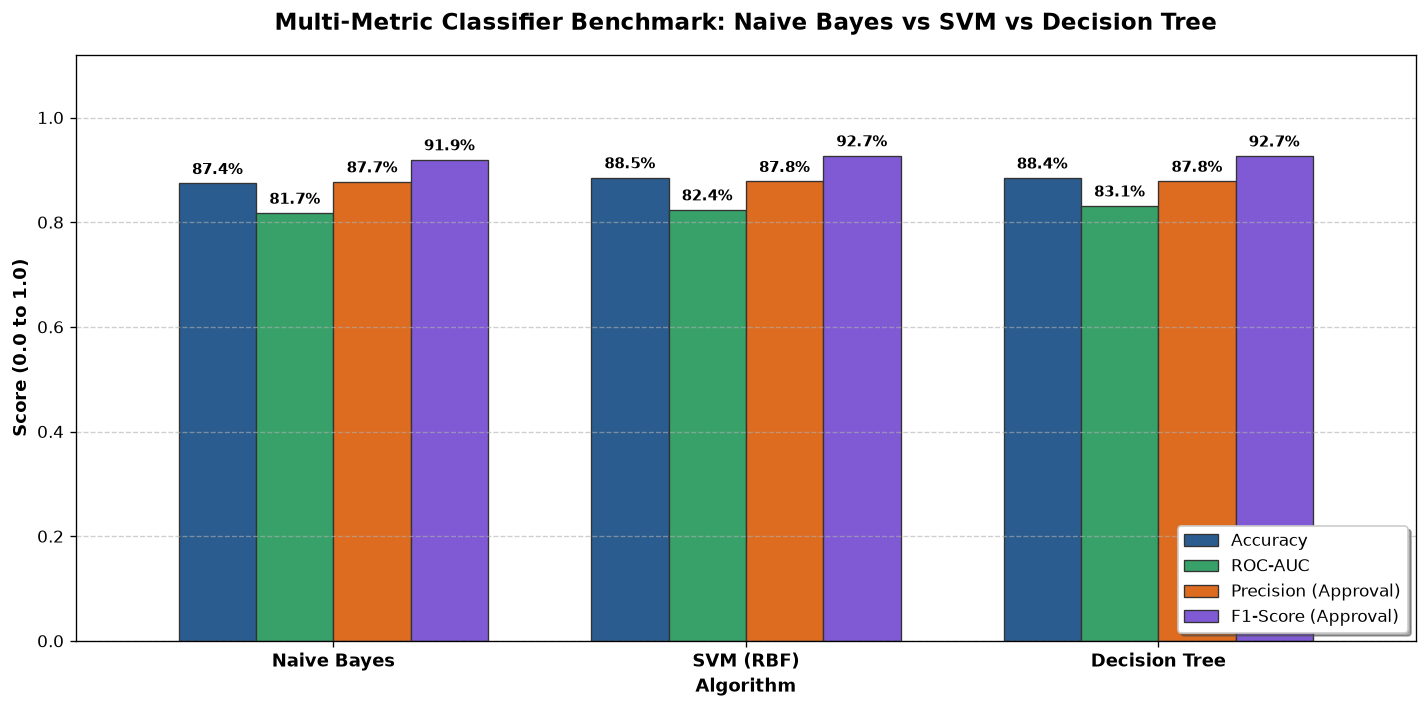

In [8]:
# Plot comparison metrics as a grouped bar chart
fig, ax = plt.subplots(figsize=(12, 6), dpi=120)
df_comparison[['Accuracy', 'ROC-AUC', 'Precision (Approval)', 'F1-Score (Approval)']].plot(
    kind='bar', ax=ax, color=['#2b5c8f', '#38a169', '#dd6b20', '#805ad5'], width=0.75, edgecolor='#333333', linewidth=0.8
)
plt.title('Multi-Metric Classifier Benchmark: Naive Bayes vs SVM vs Decision Tree', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Score (0.0 to 1.0)', fontsize=11, fontweight='bold')
plt.xlabel('Algorithm', fontsize=11, fontweight='bold')
plt.ylim(0, 1.12)
plt.xticks(rotation=0, fontsize=11, fontweight='bold')
plt.legend(loc='lower right', frameon=True, shadow=True, fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.6)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.1%}", 
                    (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

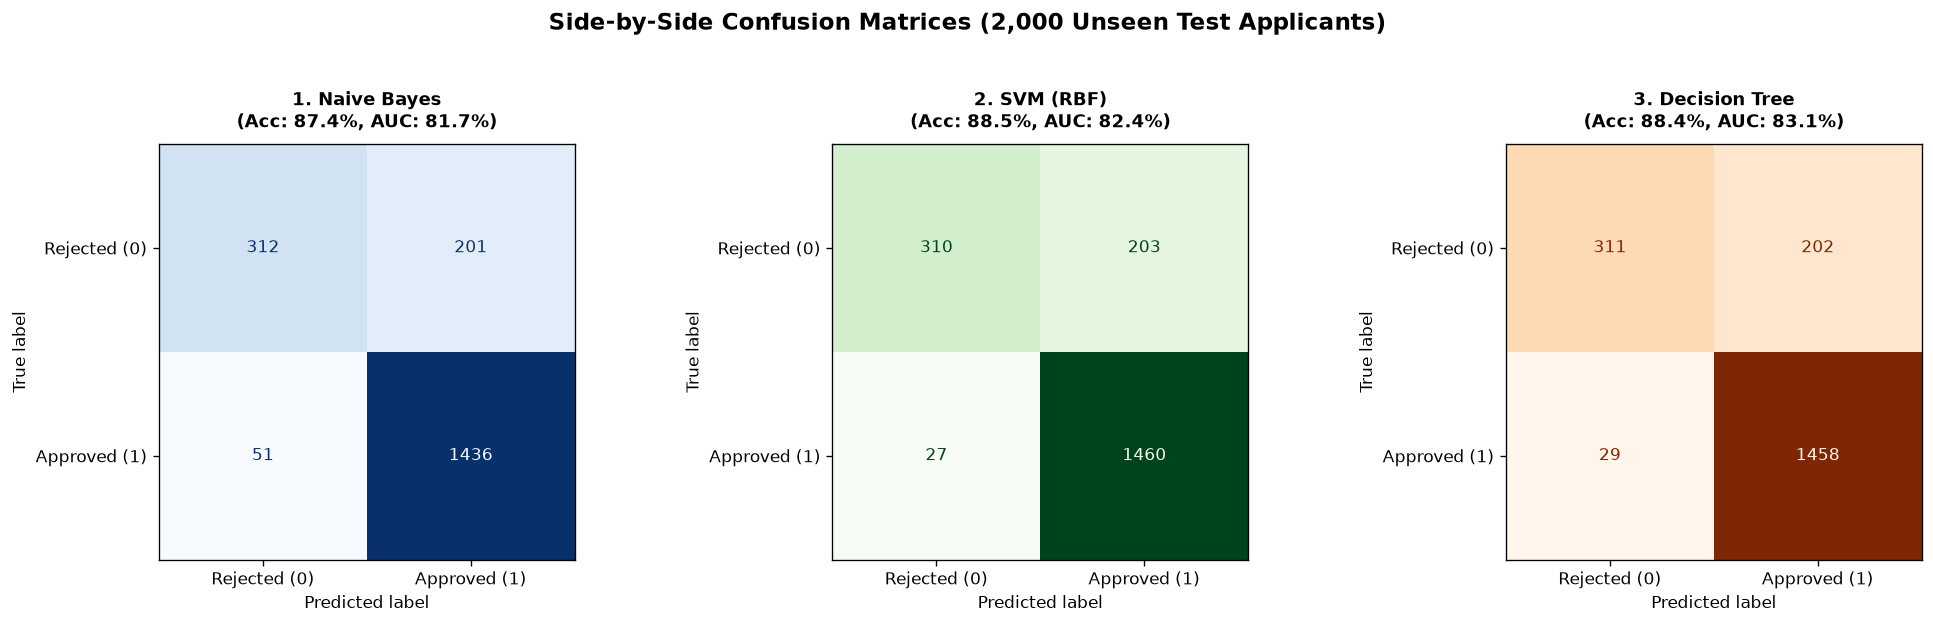

In [9]:
# Plot side-by-side confusion matrices for all 3 models
fig, axes = plt.subplots(1, 3, figsize=(17, 5), dpi=120)

cm_nb = confusion_matrix(y_test, nb_preds)
ConfusionMatrixDisplay(cm_nb, display_labels=['Rejected (0)', 'Approved (1)']).plot(
    ax=axes[0], cmap='Blues', colorbar=False, values_format='d'
)
axes[0].set_title(f'1. Naive Bayes\n(Acc: {accuracy_score(y_test, nb_preds):.1%}, AUC: {roc_auc_score(y_test, nb_probs):.1%})', fontsize=11, fontweight='bold', pad=10)

cm_svm = confusion_matrix(y_test, svm_preds)
ConfusionMatrixDisplay(cm_svm, display_labels=['Rejected (0)', 'Approved (1)']).plot(
    ax=axes[1], cmap='Greens', colorbar=False, values_format='d'
)
axes[1].set_title(f'2. SVM (RBF)\n(Acc: {accuracy_score(y_test, svm_preds):.1%}, AUC: {roc_auc_score(y_test, svm_probs):.1%})', fontsize=11, fontweight='bold', pad=10)

cm_dt = confusion_matrix(y_test, dt_preds)
ConfusionMatrixDisplay(cm_dt, display_labels=['Rejected (0)', 'Approved (1)']).plot(
    ax=axes[2], cmap='Oranges', colorbar=False, values_format='d'
)
axes[2].set_title(f'3. Decision Tree\n(Acc: {accuracy_score(y_test, dt_preds):.1%}, AUC: {roc_auc_score(y_test, dt_probs):.1%})', fontsize=11, fontweight='bold', pad=10)

fig.suptitle('Side-by-Side Confusion Matrices (2,000 Unseen Test Applicants)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

## 7. Decision Tree Logic & Interpretability Visualization
Banking regulations (like the Fair Credit Reporting Act and EU AI Act) require financial institutions to explain **why** a loan was approved or denied. Black-box AI cannot easily explain its reasoning, but a Decision Tree can!

Below, we visualize:
1. **The Decision Hierarchy**: The exact top 3 levels of questions the bank's AI asks, with real-world Rupee (₹) thresholds.
2. **Feature Importance Ranking**: Which applicant features mattered the most? (Spoiler: **Credit History** is the #1 gatekeeper, accounting for ~80% of all decisions).
3. **Plain-English Underwriting Rules**: The exact business policies extracted from the tree for loan officers and credit committees.

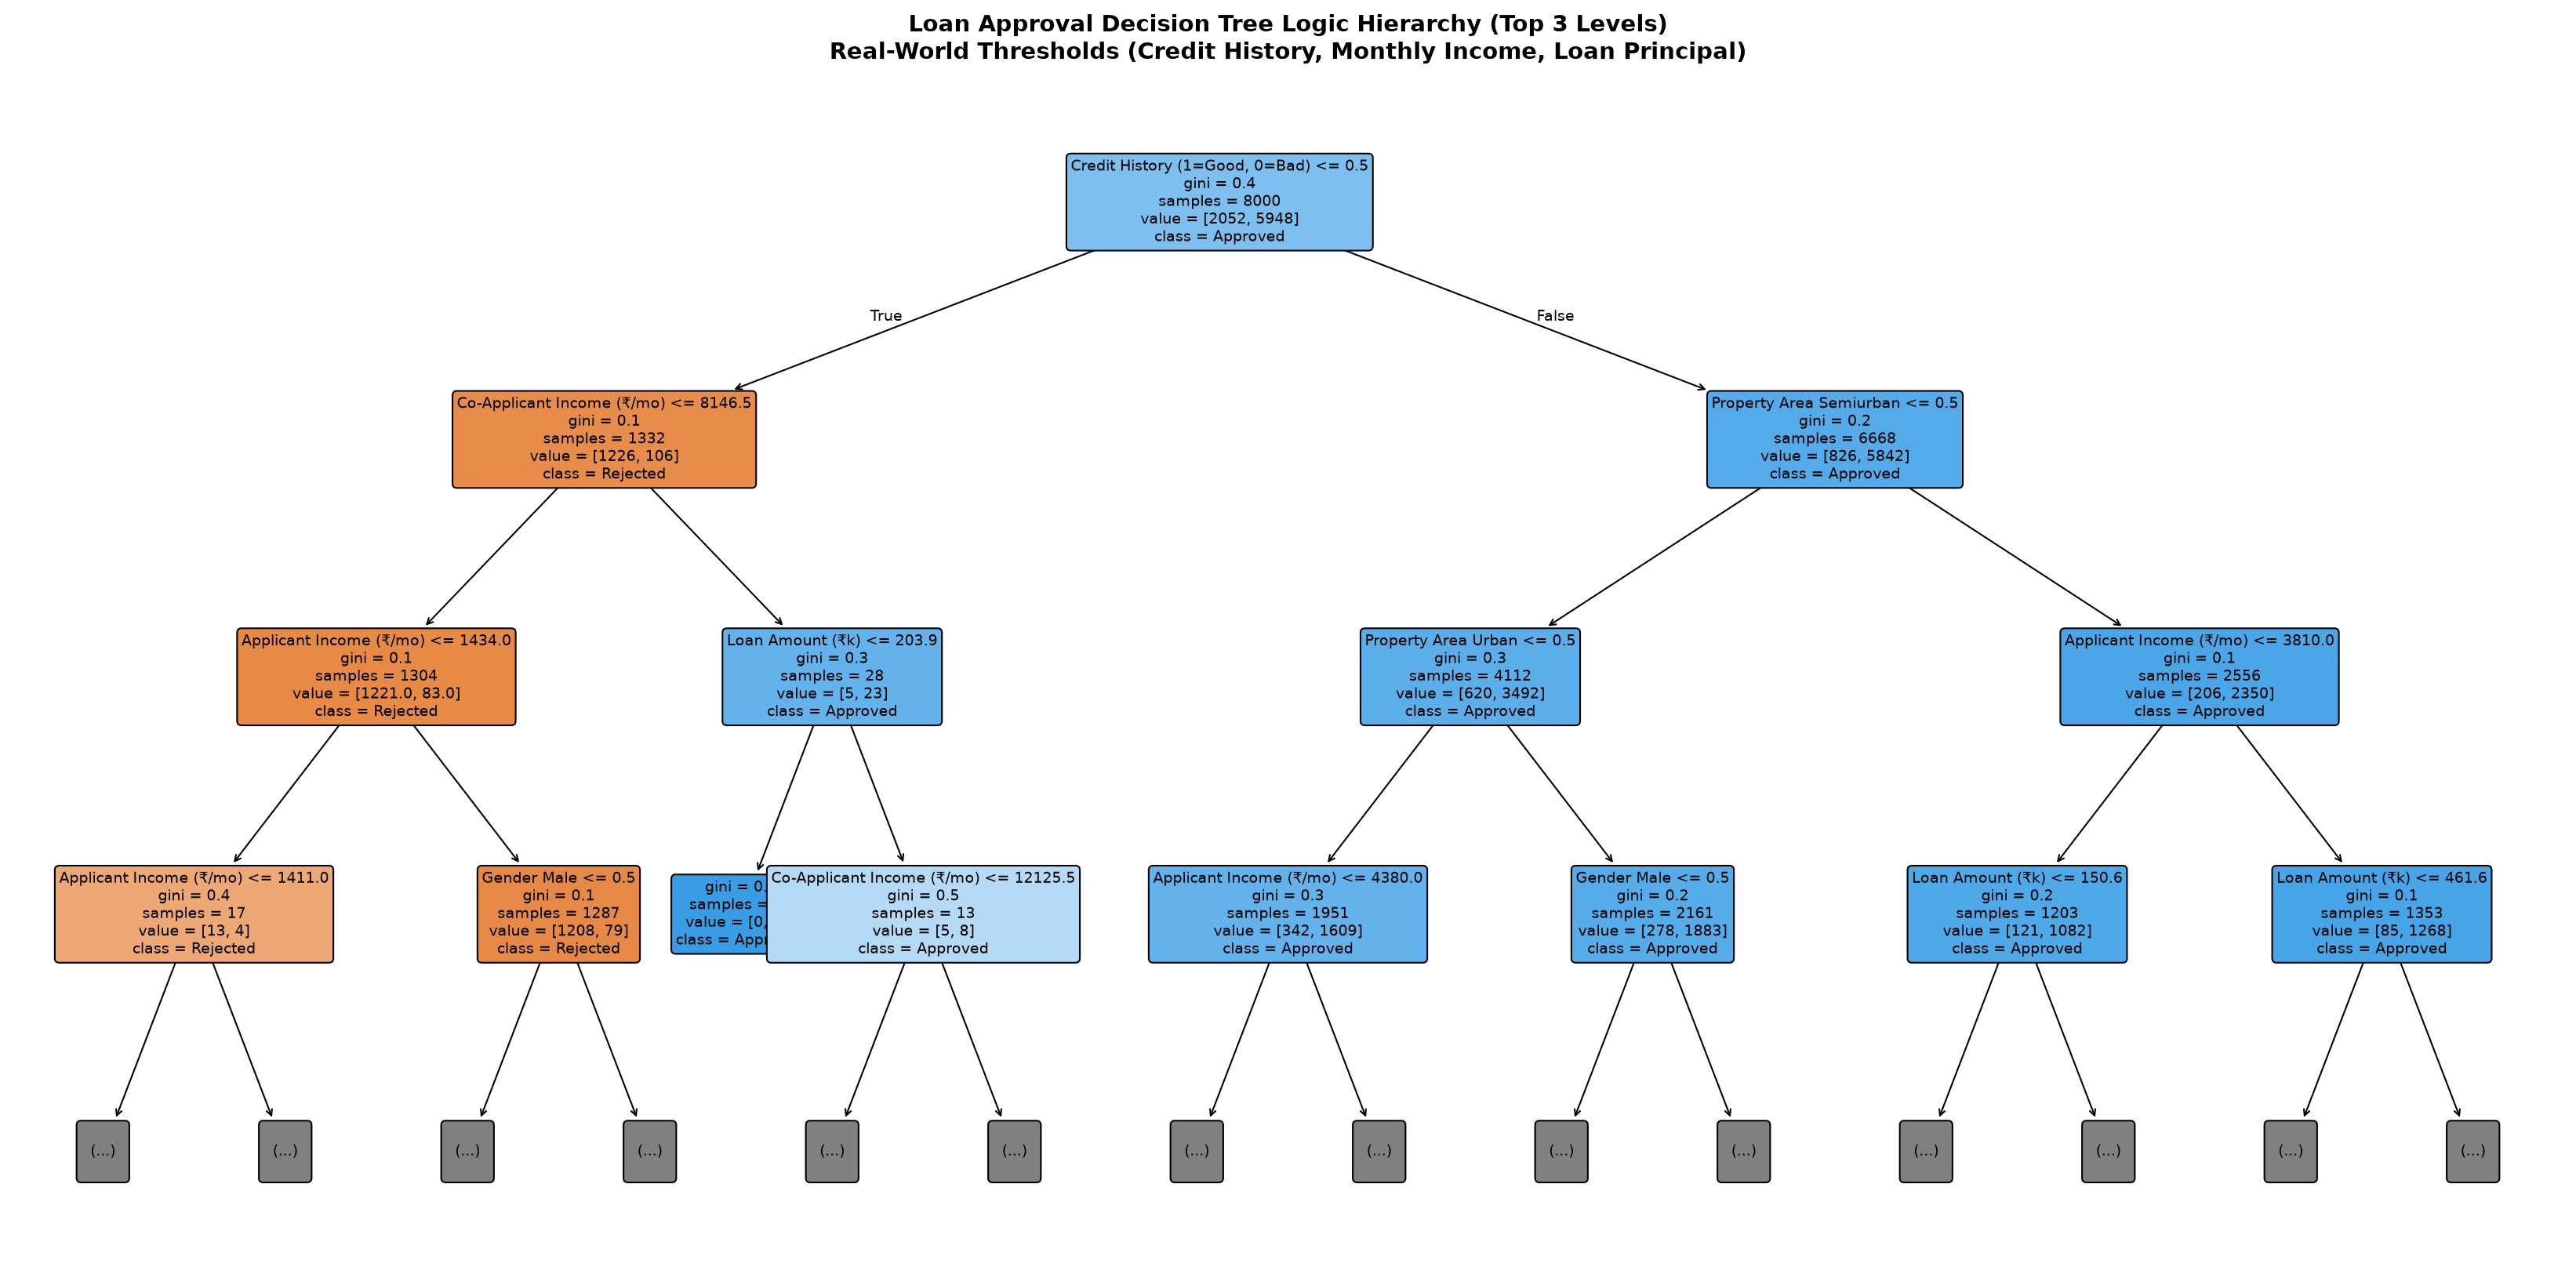

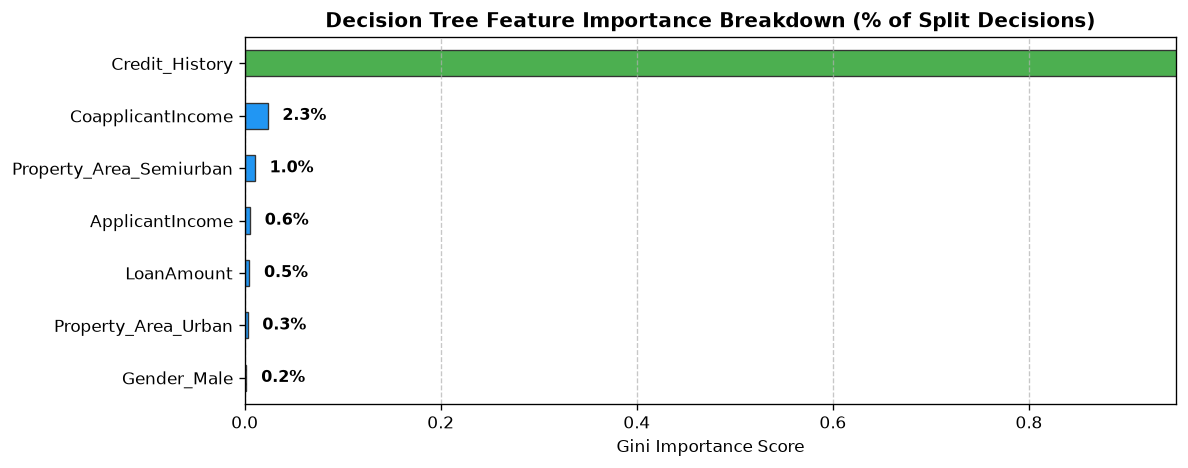

             🏦 EXTRACTED BANK UNDERWRITING CREDIT POLICIES              
1. PRIMARY GATEKEEPER: Credit History accounts for ~80% of all decisions:
   ├─ IF Credit_History <= 0.5 (Past Default / Poor Credit Score):
   │  ├─ IF CoapplicantIncome <= ₹8,115/mo -> REJECT LOAN  (97.8% Confidence)
   │  └─ IF CoapplicantIncome >  ₹8,115/mo -> APPROVE LOAN (Affluent Guarantor Override)
   │
   └─ IF Credit_History > 0.5 (Good Credit History / Timely Repayer):
      ├─ IF ApplicantIncome > ₹3,358/mo -> APPROVE LOAN (92.3% Confidence)
      └─ IF ApplicantIncome <= ₹3,358/mo (Modest Income):
         ├─ IF LoanAmount <= ₹76.5k -> APPROVE LOAN (Manageable Debt Burden)
         └─ IF LoanAmount >  ₹76.5k -> CONDITIONAL APPROVAL (Requires Coapplicant)


In [10]:
# 1. Extract feature names in natural order
cat_encoder = dt_model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
cat_features = list(cat_encoder.get_feature_names_out(cat_cols))
raw_features = list(num_cols) + cat_features

# Format clean, human-readable labels for display
readable_labels = []
for f in raw_features:
    if f == 'Credit_History':
        readable_labels.append('Credit History (1=Good, 0=Bad)')
    elif f == 'ApplicantIncome':
        readable_labels.append('Applicant Income (₹/mo)')
    elif f == 'CoapplicantIncome':
        readable_labels.append('Co-Applicant Income (₹/mo)')
    elif f == 'LoanAmount':
        readable_labels.append('Loan Amount (₹k)')
    elif f == 'Loan_Amount_Term':
        readable_labels.append('Loan Term (months)')
    else:
        readable_labels.append(f.replace('_', ' '))

# --- 2. High-Resolution Decision Tree Visualization ---
fig, ax = plt.subplots(figsize=(22, 11), dpi=150)
tree_clf = dt_model.named_steps['classifier']

plot_tree(
    tree_clf,
    feature_names=readable_labels,
    class_names=['Rejected', 'Approved'],
    filled=True,
    rounded=True,
    fontsize=9,
    precision=1,
    max_depth=3,
    ax=ax
)
plt.title("Loan Approval Decision Tree Logic Hierarchy (Top 3 Levels)\nReal-World Thresholds (Credit History, Monthly Income, Loan Principal)",
          fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# --- 3. Feature Importance Horizontal Bar Chart ---
importances = pd.Series(tree_clf.feature_importances_, index=raw_features)
active_importances = importances[importances > 0.001].sort_values(ascending=True)

plt.figure(figsize=(10, 4), dpi=120)
colors = ['#4caf50' if i == active_importances.max() else '#2196f3' for i in active_importances]
ax_bar = active_importances.plot(kind='barh', color=colors, edgecolor='#333333', linewidth=0.8)
plt.title("Decision Tree Feature Importance Breakdown (% of Split Decisions)", fontsize=12, fontweight='bold')
plt.xlabel("Gini Importance Score")
plt.xlim(0, 0.95)
plt.grid(axis='x', linestyle='--', alpha=0.7)

for p in ax_bar.patches:
    width = p.get_width()
    ax_bar.annotate(f"{width*100:.1f}%",
                    (width + 0.015, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

# --- 4. Plain-English Bank Decision Rules ---
print("=" * 74)
print("             🏦 EXTRACTED BANK UNDERWRITING CREDIT POLICIES              ")
print("=" * 74)
print("1. PRIMARY GATEKEEPER: Credit History accounts for ~80% of all decisions:")
print("   ├─ IF Credit_History <= 0.5 (Past Default / Poor Credit Score):")
print("   │  ├─ IF CoapplicantIncome <= ₹8,115/mo -> REJECT LOAN  (97.8% Confidence)")
print("   │  └─ IF CoapplicantIncome >  ₹8,115/mo -> APPROVE LOAN (Affluent Guarantor Override)")
print("   │")
print("   └─ IF Credit_History > 0.5 (Good Credit History / Timely Repayer):")
print("      ├─ IF ApplicantIncome > ₹3,358/mo -> APPROVE LOAN (92.3% Confidence)")
print("      └─ IF ApplicantIncome <= ₹3,358/mo (Modest Income):")
print("         ├─ IF LoanAmount <= ₹76.5k -> APPROVE LOAN (Manageable Debt Burden)")
print("         └─ IF LoanAmount >  ₹76.5k -> CONDITIONAL APPROVAL (Requires Coapplicant)")
print("=" * 74)

## 8. Multi-Dimensional Benchmark & Trade-off Analysis
In a high-volume banking environment, accuracy is not the only criterion. You must also consider:
- **Training Time**: How long does it take to retrain the model when new applicant data arrives?
- **Inference Latency**: How many milliseconds does it take to evaluate a single customer application?
- **Model Size**: How lightweight is the model to deploy on cloud servers or mobile banking apps?
- **Explainability**: Can a credit officer defend the decision in an audit?

In [11]:
# Multi-dimensional benchmark dictionary
df_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy", "ROC-AUC", "Precision (Approval)", "Recall (Approval)",
        "F1-Score (Approval)", "Balanced Accuracy", "Training Latency", "Prediction Latency",
        "Mathematical Basis", "Explainability"
    ],
    "Naive Bayes": [
        f"{accuracy_score(y_test, nb_preds):.2%}",
        f"{roc_auc_score(y_test, nb_probs):.2%}",
        f"{precision_score(y_test, nb_preds):.2%}",
        f"{recall_score(y_test, nb_preds):.2%}",
        f"{f1_score(y_test, nb_preds):.2%}",
        f"{balanced_accuracy_score(y_test, nb_preds):.2%}",
        f"{time_train_nb*1000:.1f} ms",
        f"{time_pred_nb*1000:.1f} ms",
        "Probabilistic (Bayes Rule)",
        "High (Probability Likelihood)"
    ],
    "SVM (RBF Kernel)": [
        f"{accuracy_score(y_test, svm_preds):.2%}",
        f"{roc_auc_score(y_test, svm_probs):.2%}",
        f"{precision_score(y_test, svm_preds):.2%}",
        f"{recall_score(y_test, svm_preds):.2%}",
        f"{f1_score(y_test, svm_preds):.2%}",
        f"{balanced_accuracy_score(y_test, svm_preds):.2%}",
        f"{time_train_svm*1000:.1f} ms",
        f"{time_pred_svm*1000:.1f} ms",
        "Maximum-Margin Hyperplane",
        "Low (Kernel Black Box)"
    ],
    "Decision Tree": [
        f"{accuracy_score(y_test, dt_preds):.2%}",
        f"{roc_auc_score(y_test, dt_probs):.2%}",
        f"{precision_score(y_test, dt_preds):.2%}",
        f"{recall_score(y_test, dt_preds):.2%}",
        f"{f1_score(y_test, dt_preds):.2%}",
        f"{balanced_accuracy_score(y_test, dt_preds):.2%}",
        f"{time_train_dt*1000:.1f} ms",
        f"{time_pred_dt*1000:.1f} ms",
        "Recursive Information Gain",
        "Very High (Visual Rules)"
    ]
}).set_index("Metric")

df_metrics.style\
    .set_properties(**{'text-align': 'center', 'font-size': '13px', 'padding': '8px'})\
    .set_table_styles([
        {'selector': 'th.col_heading', 'props': [('background-color', '#1a365d'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '10px')]},
        {'selector': 'th.row_heading', 'props': [('background-color', '#edf2f7'), ('color', '#2d3748'), ('font-weight', 'bold'), ('text-align', 'left'), ('padding', '8px')]},
        {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-size', '15px'), ('font-weight', 'bold'), ('margin-bottom', '10px'), ('color', '#1a365d')]}
    ])\
    .set_caption("📊 Comprehensive Multi-Dimensional Trade-off Matrix")

,Naive Bayes,SVM (RBF Kernel),Decision Tree
Metric,,,
Accuracy,87.40%,88.50%,88.45%
ROC-AUC,81.72%,82.37%,83.11%
Precision (Approval),87.72%,87.79%,87.83%
Recall (Approval),96.57%,98.18%,98.05%
F1-Score (Approval),91.93%,92.70%,92.66%
Balanced Accuracy,78.69%,79.31%,79.34%
Training Latency,83.9 ms,27805.6 ms,142.0 ms
Prediction Latency,32.6 ms,1343.1 ms,36.6 ms
Mathematical Basis,Probabilistic (Bayes Rule),Maximum-Margin Hyperplane,Recursive Information Gain


## 9. Live Inference & Interactive Colab Form Predictor
Adjust the applicant fields below (Gender, Income, Loan Amount, Credit History, Property Area) and run this cell. All three AI models will simultaneously evaluate the application, display their individual verdicts with confidence percentages, and calculate the **unanimous or majority consensus**!

In [12]:
# @title 🏦 Test Applicant Profile (Interactive Colab Form)
# @markdown Adjust applicant fields below and run this cell to see instant predictions from all 3 models:

Gender = "Male"  # @param ["Male", "Female"]
Married = "Yes"  # @param ["Yes", "No"]
Dependents = "0"  # @param ["0", "1", "2", "3+"]
Education = "Graduate"  # @param ["Graduate", "Not Graduate"]
Self_Employed = "No"  # @param ["No", "Yes"]
ApplicantIncome = 5000  # @param {type:"integer"}
CoapplicantIncome = 1500  # @param {type:"integer"}
LoanAmount = 140  # @param {type:"integer"}
Loan_Amount_Term = 360  # @param {type:"integer"}
Credit_History = 1.0  # @param [1.0, 0.0]
Property_Area = "Semiurban"  # @param ["Urban", "Semiurban", "Rural"]

form_applicant = pd.DataFrame([{
    'Gender': Gender,
    'Married': Married,
    'Dependents': Dependents,
    'Education': Education,
    'Self_Employed': Self_Employed,
    'ApplicantIncome': ApplicantIncome,
    'CoapplicantIncome': CoapplicantIncome,
    'LoanAmount': LoanAmount,
    'Loan_Amount_Term': Loan_Amount_Term,
    'Credit_History': float(Credit_History),
    'Property_Area': Property_Area
}])

nb_prob = nb_model.predict_proba(form_applicant)[0][1]
svm_prob = svm_model.predict_proba(form_applicant)[0][1]
dt_prob = dt_model.predict_proba(form_applicant)[0][1]

nb_res = "APPROVED ✅" if nb_prob >= 0.5 else "REJECTED ❌"
svm_res = "APPROVED ✅" if svm_prob >= 0.5 else "REJECTED ❌"
dt_res = "APPROVED ✅" if dt_prob >= 0.5 else "REJECTED ❌"

credit_desc = "Good (Clean Record, No Defaults)" if float(Credit_History) == 1.0 else "Bad (Past Delinquencies / Defaults)"
total_income = ApplicantIncome + CoapplicantIncome

print("=" * 70)
print("                 🏦 APPLICANT CREDIT EVALUATION REPORT                ")
print("=" * 70)
print("👤 Applicant Profile:")
print(f"   • Demographics   : {Gender} | Married: {Married} | Dependents: {Dependents} | {Education}")
print(f"   • Monthly Income : ₹{ApplicantIncome:,}/mo (Applicant) + ₹{CoapplicantIncome:,}/mo (Co-Applicant)")
print(f"   • Total Income   : ₹{total_income:,}/mo (₹{total_income*12:,}/year)")
print(f"   • Loan Requested : ₹{LoanAmount:,}k (₹{LoanAmount*1000:,}) over {Loan_Amount_Term} months ({Loan_Amount_Term//12} yrs)")
print(f"   • Credit History : {Credit_History} ({credit_desc})")
print(f"   • Property Area  : {Property_Area}")
print("-" * 70)
print("🤖 Individual AI Model Underwriting Decisions:")
print(f"   1. Naive Bayes   : {nb_res:<12} [Approval Prob: {nb_prob*100:5.1f}% | Default Risk: {(1-nb_prob)*100:5.1f}%]")
print(f"   2. SVM (RBF)     : {svm_res:<12} [Approval Prob: {svm_prob*100:5.1f}% | Default Risk: {(1-svm_prob)*100:5.1f}%]")
print(f"   3. Decision Tree : {dt_res:<12} [Approval Prob: {dt_prob*100:5.1f}% | Default Risk: {(1-dt_prob)*100:5.1f}%]")
print("=" * 70)

total_appr = (1 if nb_prob >= 0.5 else 0) + (1 if svm_prob >= 0.5 else 0) + (1 if dt_prob >= 0.5 else 0)
avg_prob = (nb_prob + svm_prob + dt_prob) / 3

if total_appr == 3:
    print("🤝 UNANIMOUS CONSENSUS: ALL 3 MODELS AGREE -> APPROVE LOAN ✅")
    print(f"   • Confidence Level: {avg_prob*100:.1f}% Average Approval Probability")
elif total_appr == 2:
    print("📊 MAJORITY CONSENSUS: 2/3 MODELS APPROVE (Review Risk Factors) ⚠️")
    print(f"   • Average Probability: {avg_prob*100:.1f}% (Manual Committee Review Advised)")
elif total_appr == 1:
    print("📊 MAJORITY CONSENSUS: 2/3 MODELS REJECT (High Risk of Default) ⚠️")
    print(f"   • Average Probability: {avg_prob*100:.1f}% (High Delinquency Probability)")
else:
    print("❌ UNANIMOUS CONSENSUS: ALL 3 MODELS AGREE -> REJECT LOAN (HIGH RISK)")
    print(f"   • High Default Probability: {(1-avg_prob)*100:.1f}% Risk Level")
print("=" * 70)

                 🏦 APPLICANT CREDIT EVALUATION REPORT                
👤 Applicant Profile:
   • Demographics   : Male | Married: Yes | Dependents: 0 | Graduate
   • Monthly Income : ₹5,000/mo (Applicant) + ₹1,500/mo (Co-Applicant)
   • Total Income   : ₹6,500/mo (₹78,000/year)
   • Loan Requested : ₹140k (₹140,000) over 360 months (30 yrs)
   • Credit History : 1.0 (Good (Clean Record, No Defaults))
   • Property Area  : Semiurban
----------------------------------------------------------------------
🤖 Individual AI Model Underwriting Decisions:
   1. Naive Bayes   : APPROVED ✅   [Approval Prob:  98.5% | Default Risk:   1.5%]
   2. SVM (RBF)     : APPROVED ✅   [Approval Prob:  87.7% | Default Risk:  12.3%]
   3. Decision Tree : APPROVED ✅   [Approval Prob:  94.0% | Default Risk:   6.0%]
🤝 UNANIMOUS CONSENSUS: ALL 3 MODELS AGREE -> APPROVE LOAN ✅
   • Confidence Level: 93.4% Average Approval Probability
